
# Predicción del riesgo crediticio mediante Machine Learning

## 1. Objetivo del proyecto

El objetivo de este proyecto es desarrollar y comparar modelos de clasificación para predecir el riesgo crediticio de los solicitantes de préstamos, utilizando el conjunto de datos *German Credit Risk*.

Se implementan tres algoritmos: regresión logística, árbol de decisión y Random Forest. Su desempeño se compara mediante métricas como Accuracy y AUC para identificar cuál ofrece mejores resultados predictivos.

## 2. Tecnologías utilizadas

- Python
- Pandas y NumPy
- Scikit-learn
- Matplotlib y Seaborn
- Google Colab

## 3. Descripción general de los datos

El conjunto de datos contiene 1.000 registros y 20 variables originales relacionadas con las características personales y financieras de los solicitantes.

La variable objetivo representa el riesgo crediticio, codificado como:

- **0:** buen riesgo crediticio.
- **1:** mal riesgo crediticio.

El propósito es identificar patrones asociados al riesgo y evaluar la capacidad de los modelos para clasificar correctamente a los solicitantes.



# Libreria pandas y base de datos

In [1]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

df = pd.read_csv(url, sep=" ", header=None)

df.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


# Revisamos la variable respuesta

In [2]:
columnas = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

df.columns = columnas

df.head()

df["credit_risk"].value_counts()

,count
credit_risk,
1,700
2,300


# Conversión variable respuesta

In [3]:
df["credit_risk"] = df["credit_risk"].map({
    1: 0,  # Buen riesgo
    2: 1   # Mal riesgo
})

df["credit_risk"].value_counts()

,count
credit_risk,
0,700
1,300


# Predictores y variable respuesta

In [4]:
X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

print("X:", X.shape)
print("y:", y.shape)

X: (1000, 20)
y: (1000,)


# Analisis exploratorio de los datos



In [5]:
df.isnull().sum()
df.dtypes

,0
checking_account,object
duration,int64
credit_history,object
purpose,object
credit_amount,int64
savings_account,object
employment,object
installment_rate,int64
personal_status_sex,object
other_debtors,object


In [6]:
df.describe()

,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,credit_risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,0.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,0.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,0.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,0.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,1.000000


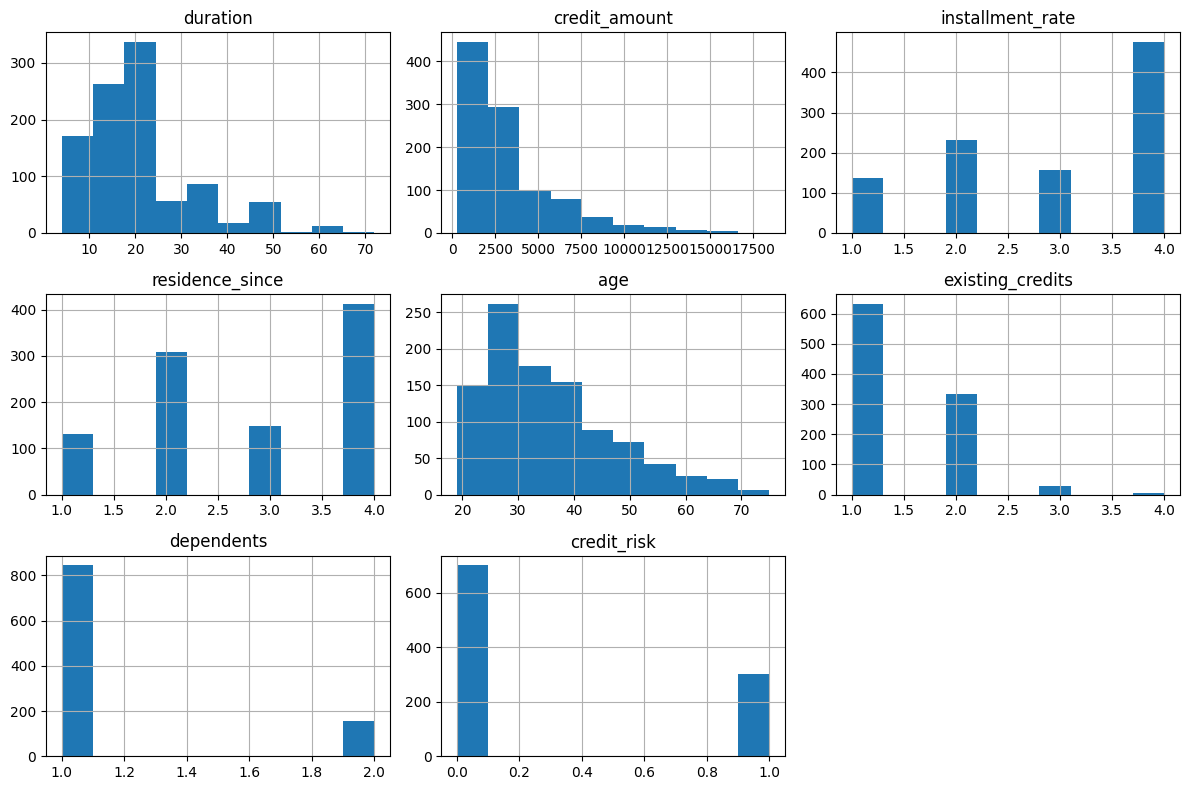

In [7]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [8]:
categoricas = df.select_dtypes(include="object").columns

for col in categoricas:
    print("\n", col)
    print(df[col].value_counts())


 checking_account
checking_account
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64

 credit_history
credit_history
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64

 purpose
purpose
A43     280
A40     234
A42     181
A41     103
A49      97
A46      50
A45      22
A44      12
A410     12
A48       9
Name: count, dtype: int64

 savings_account
savings_account
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

 employment
employment
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64

 personal_status_sex
personal_status_sex
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

 other_debtors
other_debtors
A101    907
A103     52
A102     41
Name: count, dtype: int64

 property
property
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

 other_installment_plans
other_installment_plans
A143    814
A141    139
A142     47
Name: count, 

In [9]:
variables_categoricas = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

for variable in variables_categoricas:
    tabla = pd.crosstab(
        df[variable],
        df["credit_risk"]
    )

    # Frecuencias absolutas
    tabla.columns = ["Buen_riesgo_n", "Mal_riesgo_n"]

    # Proporciones dentro de cada categoría
    proporciones = pd.crosstab(
        df[variable],
        df["credit_risk"],
        normalize="index"
    ) * 100

    proporciones.columns = ["Buen_riesgo_%", "Mal_riesgo_%"]

    # Unir frecuencias y porcentajes
    tabla_final = pd.concat([tabla, proporciones], axis=1)

    print("=" * 60)
    print(variable)
    print("=" * 60)
    print(tabla_final.round(2))

checking_account
                  Buen_riesgo_n  Mal_riesgo_n  Buen_riesgo_%  Mal_riesgo_%
checking_account                                                          
A11                         139           135          50.73         49.27
A12                         164           105          60.97         39.03
A13                          49            14          77.78         22.22
A14                         348            46          88.32         11.68
credit_history
                Buen_riesgo_n  Mal_riesgo_n  Buen_riesgo_%  Mal_riesgo_%
credit_history                                                          
A30                        15            25          37.50         62.50
A31                        21            28          42.86         57.14
A32                       361           169          68.11         31.89
A33                        60            28          68.18         31.82
A34                       243            50          82.94         17.06
purpose

se observa que a mayor cantidad de dinero en las cuentas corrientes, mayor es la proporción de que ser categorizados con riesgo crediticio positivo.

En cuanto a historial crediticio tenemos tambien que las proporciones cambian en cada una de las categorias, y se observa que las personas en la categoria de retrasos previos y cuenta critica otros criticos la mayoria tiene riesgo crediticio positivo, tambien es de destacar que la mayoria de inviduos en los datos estan en la categoria de creditos pagados correctamente y cuenta critica/otros creditos

Para proposito no es tan amplio el rango de variabilidad de la proporcion es las categorias, de hecho lo mismo sucede con las demás.

En la variable de ahorros se observa la mayoria de personas entre mas ahorros tienen una proporción de mayor con riesgo crediticio positivo, adicionalmente la mayoria de individuos estan en la categoria con menor ahorro

para otros deudores se tiene que la mayor propoción de personas con riesgo crediticio bueno son lo que precisamente son garantes, donde se encuentran adicionalmente la mayoria de los clientes es en la categoria ninguno, ni garantes ni co- solicitantes

En propiedades se observa que la mayor proporción con de personas con riesgo crediticio bueno estan en la categoria de bienes raices

para la variable de otros planes de cuotas se tiene que el porcentaje mas alto de buen riesgo crediticio esta en la categoria ninguno, es decir no tener ningun credito con otra entidad, la mayoria de personas esta en la categoria ninguna, es decir no tienen creditos con otros bancos ni tiendas

En cuanto a vivienda la mayor proporción se encuentra en la categoria de vivienda propia, además que tiene bastante relevancia ya que la mayoria de inviduos se encuentran en esa categoria

Aunque en la variable trabajo/ocupación observemos que la mayor proporción de personas con un riesgo credicitio bueno se encuentre en la categoria de enpleado no cualificado/residente, la mayoria de observaciones son personas que estan en la categoria empleado cualificado/ funcionario.

para la variable de telefono se observa que la mayoria de personas no tienen el telefono registrado no hay muchas diferencias en las proporciones de tener o no el telefono registrado y tener un buen o mal riesgo crediticio

Tambien se observa que la mayoria de las personas en los datos son trabajadores extranjeros la mayor proporcion de personas con riesgo crediticio bueno son personas no extranjeras, aunque las personas en esta categoria son muy pocas













## 4. Preparación de los datos

En esta etapa se preparan los datos para su utilización en los modelos de Machine Learning.

- **Codificación de variables:** se utiliza One-Hot Encoding para transformar las variables categóricas en variables numéricas.
- **Variable objetivo:** se codifica el riesgo crediticio como 0 (buen riesgo) y 1 (mal riesgo).
- **División de los datos:** se separan los datos en conjuntos de entrenamiento (80 %) y prueba (20 %).

El conjunto final de predictores contiene 48 variables después de la codificación. Los datos de entrenamiento se utilizan para ajustar los modelos y los datos de prueba para evaluar su capacidad predictiva.

# ONE-HOT-ENCODIGN (variables categoricas en binarias- dummy)

In [10]:
variables_numericas = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

variables_categoricas = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

In [18]:
X = df[variables_numericas + variables_categoricas]
y = df["credit_risk"]

X.head()

,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,checking_account,credit_history,purpose,savings_account,employment,personal_status_sex,other_debtors,property,other_installment_plans,housing,job,telephone,foreign_worker
0,6,1169,4,4,67,2,1,A11,A34,A43,A65,A75,A93,A101,A121,A143,A152,A173,A192,A201
1,48,5951,2,2,22,1,1,A12,A32,A43,A61,A73,A92,A101,A121,A143,A152,A173,A191,A201
2,12,2096,2,3,49,1,2,A14,A34,A46,A61,A74,A93,A101,A121,A143,A152,A172,A191,A201
3,42,7882,2,4,45,1,2,A11,A32,A42,A61,A74,A93,A103,A122,A143,A153,A173,A191,A201
4,24,4870,3,4,53,2,2,A11,A33,A40,A61,A73,A93,A101,A124,A143,A153,A173,A191,A201


In [17]:
X.shape

(1000, 48)

#Entrenamiento y test 80% entrenar/ 20% evaluar

In [19]:
from sklearn.model_selection import train_test_split

y = df["credit_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (800, 20)
Prueba: (200, 20)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocesador = ColumnTransformer([
    ("numericas", StandardScaler(), variables_numericas),
    ("categoricas", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), variables_categoricas)
])

modelo_logit = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(
        max_iter=10000,
        random_state=42
    ))
])

## 5. Entrenamiento de los modelos

Se entrenan tres algoritmos de clasificación supervisada para predecir el riesgo crediticio:

- **Regresión logística:** estima la probabilidad de que un solicitante pertenezca a la clase de mal riesgo crediticio.
- **Árbol de decisión:** clasifica a los solicitantes mediante reglas basadas en las características de los datos.
- **Random Forest:** combina múltiples árboles de decisión para obtener predicciones más robustas.

Los tres modelos se entrenan con el mismo conjunto de entrenamiento y se evalúan sobre el conjunto de prueba, permitiendo comparar su desempeño bajo las mismas condiciones.



##regresión logistica


In [22]:
modelo_logit.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['duration', 'credit_amount',
                                                   'installment_rate',
                                                   'residence_since', 'age',
                                                   'existing_credits',
                                                   'dependents']),
                                                 ('categoricas',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['checking_account',
                                                   'credit_history', 'purpose',
                                                   'savings_account',
                                                   'employment',
                                                   'personal_status_sex',
                                                   'other_debtors', 'property',
                                                   'other_installment_plans',
                                                   'housing', 'job',
                                                   'telephone',
                                                   'foreign_worker'])])),
                ('modelo',
                 LogisticRegression(max_iter=10000, random_state=42))])

In [23]:
# evaluamos los 200 datos de prueba en nuestro modelo para ver las predicciones

from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

y_pred = modelo_logit.predict(X_test)
y_prob = modelo_logit.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))
print("F1-score:", f1_score(y_test, y_pred))

Accuracy: 0.78
AUC: 0.8039285714285714
F1-score: 0.5925925925925926


In [24]:
#matriz de confusión:

from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_test, y_pred)

print(matriz)

[[124  16]
 [ 28  32]]


In [25]:
# precisión (mal riesgo realmente los sean)
# recall (mal riesgo detectados del modelo sobre el total de mal riesgo real)
# F1-score ( equilibrio entre precisión y recall)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       140
           1       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200



In [26]:
# Extraemos los coeficientes del modelo entrenado

preprocesador = modelo_logit.named_steps["preprocesamiento"]
regresion = modelo_logit.named_steps["modelo"]

nombres_variables = preprocesador.get_feature_names_out()

coeficientes = pd.DataFrame({
    "Variable": nombres_variables,
    "Coeficiente": regresion.coef_[0]
})

coeficientes["Magnitud"] = coeficientes["Coeficiente"].abs()

coeficientes.sort_values(
    by="Magnitud",
    ascending=False
).head(15)

,Variable,Coeficiente,Magnitud
9,categoricas__checking_account_A14,-1.498888,1.498888
25,categoricas__savings_account_A64,-1.113574,1.113574
13,categoricas__credit_history_A34,-1.098474,1.098474
14,categoricas__purpose_A41,-1.086028,1.086028
26,categoricas__savings_account_A65,-0.992211,0.992211
42,categoricas__housing_A153,-0.941179,0.941179
47,categoricas__foreign_worker_A202,-0.919363,0.919363
38,categoricas__property_A124,0.903920,0.903920
32,categoricas__personal_status_sex_A93,-0.784868,0.784868
40,categoricas__other_installment_plans_A143,-0.757775,0.757775


In [27]:
import numpy as np

coeficientes["Odds_Ratio"] = np.exp(coeficientes["Coeficiente"])

coeficientes.sort_values(
    by="Magnitud",
    ascending=False
).head(15)

,Variable,Coeficiente,Magnitud,Odds_Ratio
9,categoricas__checking_account_A14,-1.498888,1.498888,0.223378
25,categoricas__savings_account_A64,-1.113574,1.113574,0.328383
13,categoricas__credit_history_A34,-1.098474,1.098474,0.333380
14,categoricas__purpose_A41,-1.086028,1.086028,0.337555
26,categoricas__savings_account_A65,-0.992211,0.992211,0.370756
42,categoricas__housing_A153,-0.941179,0.941179,0.390167
47,categoricas__foreign_worker_A202,-0.919363,0.919363,0.398773
38,categoricas__property_A124,0.903920,0.903920,2.469263
32,categoricas__personal_status_sex_A93,-0.784868,0.784868,0.456180
40,categoricas__other_installment_plans_A143,-0.757775,0.757775,0.468708


In [28]:
import statsmodels.api as sm

X_train_procesado = preprocesador.fit_transform(X_train)

X_train_sm = sm.add_constant(X_train_procesado)

modelo_sm = sm.Logit(y_train, X_train_sm).fit()

print(modelo_sm.summary())

Optimization terminated successfully.
         Current function value: 0.445661
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:            credit_risk   No. Observations:                  800
Model:                          Logit   Df Residuals:                      751
Method:                           MLE   Df Model:                           48
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                  0.2704
Time:                        17:03:25   Log-Likelihood:                -356.53
converged:                       True   LL-Null:                       -488.69
Covariance Type:            nonrobust   LLR p-value:                 1.142e-31
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.2495      1.053      3.086      0.002       1.186       5.313
x1             0.3327      0.

In [29]:
nombres = ["const"] + list(preprocesador.get_feature_names_out())

resultados = pd.DataFrame({
    "Variable": nombres,
    "Coeficiente": modelo_sm.params,
    "p_valor": modelo_sm.pvalues
})

resultados["Odds_Ratio"] = np.exp(resultados["Coeficiente"])

resultados.sort_values("p_valor").head(15)

,Variable,Coeficiente,p_valor,Odds_Ratio
x10,categoricas__checking_account_A14,-1.630704,4.118714e-10,0.195792
x27,categoricas__savings_account_A65,-1.136973,1.873358e-04,0.320788
x3,numericas__installment_rate,0.405881,2.461412e-04,1.500624
x41,categoricas__other_installment_plans_A143,-0.888494,9.763775e-04,0.411275
x15,categoricas__purpose_A41,-1.353030,1.143894e-03,0.258456
const,const,3.249534,2.027682e-03,25.778320
x14,categoricas__credit_history_A34,-1.508921,2.264875e-03,0.221149
x39,categoricas__property_A124,1.332229,6.990569e-03,3.789481
x43,categoricas__housing_A153,-1.531358,7.068875e-03,0.216242
x18,categoricas__purpose_A43,-0.746693,7.378621e-03,0.473931


# Arbol de decisión

In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

modelo_arbol = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

modelo_arbol.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['duration', 'credit_amount',
                                                   'installment_rate',
                                                   'residence_since', 'age',
                                                   'existing_credits',
                                                   'dependents']),
                                                 ('categoricas',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['checking_account',
                                                   'credit_history', 'purpose',
                                                   'savings_account',
                                                   'employment',
                                                   'personal_status_sex',
                                                   'other_debtors', 'property',
                                                   'other_installment_plans',
                                                   'housing', 'job',
                                                   'telephone',
                                                   'foreign_worker'])])),
                ('modelo', DecisionTreeClassifier(random_state=42))])

In [ ]:
#predicciónes con los 200 datos de prueba

y_pred_arbol = modelo_arbol.predict(X_test)

print(y_pred_arbol)

[0 0 1 0 1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 1 1
 1 0 1 0 0 1 1 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 1 1 0 1 0 1
 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1
 0 1 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 0 0 1 0 1 1 1 1 0 0 1 0 1 0 0 0 0 1 0 1
 0 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 1 1 0 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1]


In [ ]:
# proporción de aciertos

from sklearn.metrics import accuracy_score

accuracy_arbol = accuracy_score(y_test, y_pred_arbol)

print("Accuracy árbol:", accuracy_arbol)

Accuracy árbol: 0.64


In [ ]:
#matriz de confusión

from sklearn.metrics import confusion_matrix

matriz_arbol = confusion_matrix(y_test, y_pred_arbol)

print(matriz_arbol)

[[100  40]
 [ 32  28]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_arbol))

              precision    recall  f1-score   support

           0       0.76      0.71      0.74       140
           1       0.41      0.47      0.44        60

    accuracy                           0.64       200
   macro avg       0.58      0.59      0.59       200
weighted avg       0.65      0.64      0.65       200



# Random Forest (200 árboles)

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

modelo_rf = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

modelo_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['duration', 'credit_amount',
                                                   'installment_rate',
                                                   'residence_since', 'age',
                                                   'existing_credits',
                                                   'dependents']),
                                                 ('categoricas',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['checking_account',
                                                   'credit_history', 'purpose',
                                                   'savings_account',
                                                   'employment',
                                                   'personal_status_sex',
                                                   'other_debtors', 'property',
                                                   'other_installment_plans',
                                                   'housing', 'job',
                                                   'telephone',
                                                   'foreign_worker'])])),
                ('modelo',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

### Validación cruzada

Se evalúa la regresión logística en cinco particiones del conjunto de entrenamiento. Se utiliza el `Pipeline` completo para que el preprocesamiento se ajuste dentro de cada partición y evitar fuga de información.

In [33]:
from sklearn.model_selection import cross_val_score

resultados_cv = cross_val_score(
    modelo_logit,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print("AUC por partición:", resultados_cv.round(3))
print("AUC promedio:", round(resultados_cv.mean(), 3))
print("Desviación estándar:", round(resultados_cv.std(), 3))

AUC por partición: [0.758 0.776 0.792 0.816 0.784]
AUC promedio: 0.785
Desviación estándar: 0.019


El AUC promedio resume la capacidad de discriminación entre las cinco particiones; la desviación estándar permite observar cuánto varía ese resultado. La prueba final sigue siendo el conjunto de prueba reservado.

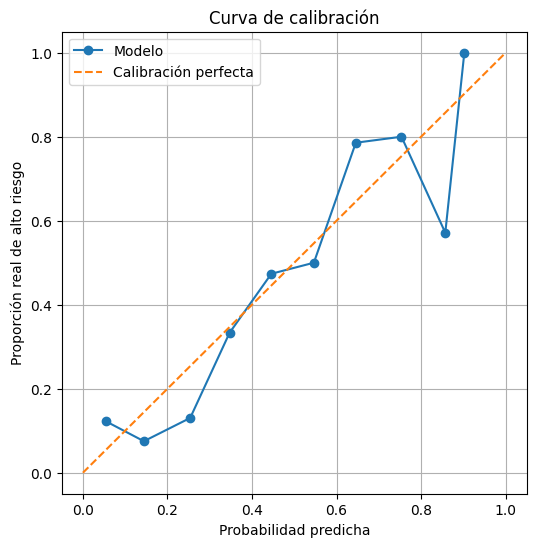

Brier score: 0.1547


In [34]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

probabilidades = modelo_logit.predict_proba(X_test)[:, 1]

fraccion_real, probabilidad_media = calibration_curve(
    y_test, probabilidades, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot(probabilidad_media, fraccion_real, "o-", label="Modelo")
plt.plot([0, 1], [0, 1], "--", label="Calibración perfecta")
plt.xlabel("Probabilidad predicha")
plt.ylabel("Proporción real de alto riesgo")
plt.title("Curva de calibración")
plt.legend()
plt.grid(True)
plt.show()

print("Brier score:", round(brier_score_loss(y_test, probabilidades), 4))

## Comparación de los modelos

La tabla resume el desempeño en el conjunto de prueba. Las métricas de la clase 1 corresponden a la identificación de créditos de alto riesgo.

In [35]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

modelos = {
    "Regresión logística": modelo_logit,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_rf
}

resultados_modelos = []

for nombre, modelo in modelos.items():
    predicciones = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    resultados_modelos.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "AUC": roc_auc_score(y_test, probabilidades),
        "Precision (alto riesgo)": precision_score(y_test, predicciones, zero_division=0),
        "Recall (alto riesgo)": recall_score(y_test, predicciones, zero_division=0),
        "F1 (alto riesgo)": f1_score(y_test, predicciones, zero_division=0)
    })

tabla_comparacion = pd.DataFrame(resultados_modelos)
display(tabla_comparacion.round(3))


Modelo,Accuracy,AUC,Precision (alto riesgo),Recall (alto riesgo),F1 (alto riesgo)
Regresión logística,0.780,0.804,0.667,0.533,0.593
Árbol de decisión,0.640,0.590,0.412,0.467,0.438
Random Forest,0.765,0.802,0.724,0.350,0.472


## Evaluación del umbral y análisis complementarios

Los coeficientes, *odds ratios* y resultados de inferencia estadística de la regresión logística ya se presentan en la sección de entrenamiento del modelo. Se omiten aquí las tablas antiguas duplicadas para evitar resultados inconsistentes con el `Pipeline` actual. A continuación se evalúan umbrales de decisión y otros diagnósticos.

In [ ]:
probabilidades = modelo_logit.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import confusion_matrix

umbrales = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for umbral in umbrales:
    pred = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    print(
        f"Umbral: {umbral} | "
        f"FP: {fp} | FN: {fn} | "
        f"Recall: {tp/(tp+fn):.2f}"
    )

Umbral: 0.2 | FP: 61 | FN: 9 | Recall: 0.85
Umbral: 0.3 | FP: 39 | FN: 12 | Recall: 0.80
Umbral: 0.4 | FP: 26 | FN: 19 | Recall: 0.68
Umbral: 0.5 | FP: 16 | FN: 28 | Recall: 0.53
Umbral: 0.6 | FP: 8 | FN: 36 | Recall: 0.40
Umbral: 0.7 | FP: 5 | FN: 47 | Recall: 0.22
Umbral: 0.8 | FP: 3 | FN: 55 | Recall: 0.08


In [ ]:
costos = []

for umbral in umbrales:
    pred = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    costo = 1 * fp + 2 * fn

    costos.append({
        "Umbral": umbral,
        "FP": fp,
        "FN": fn,
        "Costo": costo
    })

tabla_costos = pd.DataFrame(costos)

tabla_costos

,Umbral,FP,FN,Costo
0,0.2,61,9,79
1,0.3,39,12,63
2,0.4,26,19,64
3,0.5,16,28,72
4,0.6,8,36,80
5,0.7,5,47,99
6,0.8,3,55,113


In [ ]:
umbrales = np.arange(0.01, 1.00, 0.01)

resultados = []

for umbral in umbrales:
    pred = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    costo = fp + 2 * fn

    resultados.append({
        "Umbral": umbral,
        "FP": fp,
        "FN": fn,
        "Costo": costo,
        "Recall": tp / (tp + fn)
    })

tabla_umbral = pd.DataFrame(resultados)

tabla_umbral.sort_values("Costo").head(10).round(3)

,Umbral,FP,FN,Costo,Recall
34,0.35,31,14,59,0.767
35,0.36,31,14,59,0.767
33,0.34,31,14,59,0.767
36,0.37,30,15,60,0.750
37,0.38,28,16,60,0.733
30,0.31,37,12,61,0.800
32,0.33,33,14,61,0.767
41,0.42,23,19,61,0.683
38,0.39,26,18,62,0.700
40,0.41,24,19,62,0.683


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, umbrales_roc = roc_curve(y_test, probabilidades)

auc = roc_auc_score(y_test, probabilidades)

print("AUC:", auc)

AUC: 0.8036904761904762


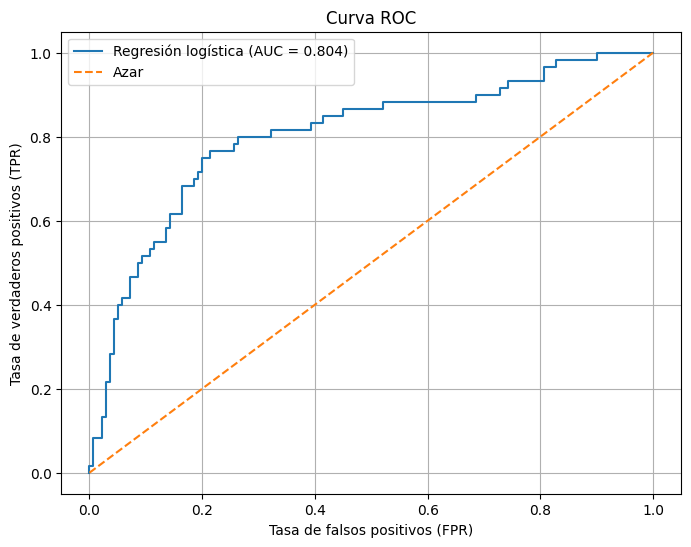

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Regresión logística (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Azar"
)

plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Curva ROC")
plt.legend()
plt.grid()

plt.show()

##relación lineal


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

resultados_bt = []

for col in variables_numericas:
    datos = df[[col, "credit_risk"]].dropna().copy()

    # Box-Tidwell requiere valores positivos
    if (datos[col] <= 0).any():
        print(f"{col}: requiere revisar valores no positivos.")
        continue

    datos[f"{col}_log"] = datos[col] * np.log(datos[col])

    X_bt = sm.add_constant(datos[[col, f"{col}_log"]])
    modelo_bt = sm.Logit(datos["credit_risk"], X_bt).fit(disp=False)

    resultados_bt.append({
        "Variable": col,
        "Coeficiente interacción": modelo_bt.params[f"{col}_log"],
        "Valor p": modelo_bt.pvalues[f"{col}_log"]
    })

tabla_bt = pd.DataFrame(resultados_bt)
display(tabla_bt.round(4))

,Variable,Coeficiente interacción,Valor p
0,duration,-0.0268,0.1610
1,credit_amount,0.0001,0.0403
2,installment_rate,0.1395,0.7048
3,residence_since,-0.1955,0.5791
4,age,0.0799,0.0233
5,existing_credits,0.2431,0.7034
6,dependents,0.2313,NaN


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

# Modelo original
modelo_original = clone(modelo_logit)
modelo_original.fit(X_train, y_train)

# Modelo alternativo: transformar dos variables numéricas
X_train_log = X_train.copy()
X_test_log = X_test.copy()

for col in ["credit_amount", "age"]:
    X_train_log[col] = np.log1p(X_train_log[col])
    X_test_log[col] = np.log1p(X_test_log[col])

modelo_transformado = clone(modelo_logit)
modelo_transformado.fit(X_train_log, y_train)

# Comparar resultados en prueba
resultados = []

for nombre, modelo, X_eval in [
    ("Original", modelo_original, X_test),
    ("Transformado", modelo_transformado, X_test_log)
]:
    pred = modelo.predict(X_eval)
    prob = modelo.predict_proba(X_eval)[:, 1]

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "F1": f1_score(y_test, pred)
    })

display(pd.DataFrame(resultados).round(3))

,Modelo,Accuracy,AUC,F1
0,Original,0.780,0.804,0.593
1,Transformado,0.775,0.792,0.587


## Multicolinealidad: factor de inflación de la varianza (VIF)

La tabla muestra los 15 predictores con mayor VIF. Los valores se recalculan al ejecutar la celda siguiente.

In [36]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Diagnóstico descriptivo de multicolinealidad usando solo los predictores X.
# No se incluye la variable objetivo ni se usan estos resultados para evaluar el modelo.
preprocesador_vif = clone(preprocesador)
X_procesado = preprocesador_vif.fit_transform(X)

# Convertir a matriz densa si el preprocesador devuelve una matriz dispersa.
if hasattr(X_procesado, "toarray"):
    X_procesado = X_procesado.toarray()

nombres_variables = preprocesador_vif.get_feature_names_out()
X_vif = pd.DataFrame(X_procesado, columns=nombres_variables, index=X.index)
X_vif = add_constant(X_vif, has_constant="add")

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.to_numpy(), j)
        for j in range(X_vif.shape[1])
    ]
})

vif = (
    vif[vif["Variable"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif.head(15).round(2))


Variable,VIF
categoricas__job_A173,14.84
categoricas__job_A172,10.83
categoricas__job_A174,8.28
categoricas__credit_history_A32,7.90
categoricas__credit_history_A34,6.73
categoricas__employment_A73,6.25
categoricas__personal_status_sex_A93,5.59
categoricas__employment_A75,5.22
categoricas__personal_status_sex_A92,5.13
categoricas__employment_A74,4.38


El VIF mide cuánto aumenta la varianza de un coeficiente por la relación lineal con otros predictores. En esta sección se calcula de forma descriptiva sobre la matriz de predictores completa, sin incluir `credit_risk`; no se utiliza para ajustar ni evaluar el modelo.

Los indicadores categóricos creados con One-Hot Encoding pueden presentar VIF más altos cuando algunas categorías son poco frecuentes o están relacionadas con otras variables. Por eso, estos valores deben interpretarse con cautela y no deben usarse, por sí solos, para eliminar variables.

##Estabilidad de los coeficientes

In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import clone

# Modelo y datos de entrenamiento
modelo_base = clone(modelo_logit)
modelo_base.fit(X_train, y_train)

nombres = modelo_base.named_steps[
    "preprocesamiento"
].get_feature_names_out()

rng = np.random.default_rng(42)
coeficientes = []

# Bootstrap: muestrear filas con reemplazo
for b in range(200):
    indices = rng.choice(len(X_train), size=len(X_train), replace=True)

    X_boot = X_train.iloc[indices]
    y_boot = y_train.iloc[indices]

    modelo_boot = clone(modelo_logit)
    modelo_boot.fit(X_boot, y_boot)

    coeficientes.append(
        modelo_boot.named_steps["modelo"].coef_[0]
    )

coeficientes = pd.DataFrame(coeficientes, columns=nombres)

# Resumen de estabilidad
resumen = pd.DataFrame({
    "Coeficiente_original": modelo_base.named_steps["modelo"].coef_[0],
    "Media_bootstrap": coeficientes.mean(),
    "Desviacion_bootstrap": coeficientes.std(),
    "Percentil_2.5": coeficientes.quantile(0.025),
    "Percentil_97.5": coeficientes.quantile(0.975)
})

resumen["Intervalo_incluye_cero"] = (
    (resumen["Percentil_2.5"] <= 0) &
    (resumen["Percentil_97.5"] >= 0)
)

display(
    resumen.assign(
        Variacion=lambda d: d["Desviacion_bootstrap"].abs()
    ).sort_values("Desviacion_bootstrap", ascending=False)
    .head(15)
    .round(3)
)

,Coeficiente_original,Media_bootstrap,Desviacion_bootstrap,Percentil_2.5,Percentil_97.5,Intervalo_incluye_cero,Variacion
categoricas__purpose_A44,-0.304,-0.345,0.496,-1.235,0.665,True,0.496
categoricas__purpose_A45,0.113,0.103,0.477,-0.786,0.962,True,0.477
categoricas__purpose_A48,-0.512,-0.506,0.474,-1.343,0.344,True,0.474
categoricas__purpose_A410,-0.715,-0.687,0.452,-1.517,0.226,True,0.452
categoricas__foreign_worker_A202,-0.919,-0.914,0.451,-1.683,-0.125,False,0.451
categoricas__other_debtors_A103,-0.505,-0.517,0.447,-1.332,0.466,True,0.447
categoricas__other_debtors_A102,0.312,0.299,0.446,-0.497,1.075,True,0.446
categoricas__credit_history_A31,0.006,0.035,0.424,-0.716,0.910,True,0.424
categoricas__savings_account_A63,-0.466,-0.486,0.418,-1.387,0.274,True,0.418
categoricas__checking_account_A13,-0.603,-0.678,0.402,-1.461,0.088,True,0.402


## Conclusiones

La comparación debe interpretarse considerando tanto la capacidad general de discriminación (**AUC**) como el desempeño al detectar la clase **1: mal riesgo crediticio**. Accuracy por sí sola no es suficiente para escoger un modelo.

La regresión logística ofrece una ventaja práctica adicional: sus coeficientes permiten estudiar la dirección y magnitud de las asociaciones con el riesgo, manteniendo presente que son asociaciones y no prueban causalidad. La validación cruzada permite comprobar si el rendimiento se mantiene razonablemente estable en distintas particiones del entrenamiento.

La curva de calibración y el Brier score complementan las métricas de clasificación: un buen AUC no garantiza que las probabilidades estimadas estén perfectamente calibradas. Además, el umbral de clasificación debe elegirse según el costo relativo de los falsos positivos y falsos negativos.

Este proyecto tiene un propósito educativo. Antes de utilizar un modelo de riesgo crediticio en decisiones reales, sería necesario validarlo con datos externos y recientes, revisar posibles sesgos y establecer controles de seguimiento.